<a href="https://colab.research.google.com/github/ulugbek-lab/computer_vision/blob/main/pytorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [81]:
import torch

In [82]:
print(torch.__version__)

2.11.0+cpu


In [83]:
print('CUDA available:', torch.cuda.is_available())

CUDA available: False


In [84]:
scalar = torch.tensor(5) # 0D tensor
print(scalar)
print(scalar.shape)

tensor(5)
torch.Size([])


In [85]:
vector = torch.tensor([1,2,3]) #1D
print('vector', vector)
print('vector shape', vector.shape)
print('vector dimension',(vector.ndim))
print('vector size', vector.size())

vector tensor([1, 2, 3])
vector shape torch.Size([3])
vector dimension 1
vector size torch.Size([3])


In [86]:
MATRIX = torch.tensor([[1,2,3], [4,5,6]]) #2D
print('MATRIX', MATRIX)
print('MATRIX shape', MATRIX.shape)
print('MATRIX dimension',(MATRIX.ndim))
print('MATRIX size', MATRIX.size())

MATRIX tensor([[1, 2, 3],
        [4, 5, 6]])
MATRIX shape torch.Size([2, 3])
MATRIX dimension 2
MATRIX size torch.Size([2, 3])


In [87]:
tensor3d = torch.stack([MATRIX, MATRIX + 10]) #3D
print('tensor', tensor3d)
print('tensor3d shape', tensor3d.shape) #
print('tensor dimension', tensor3d.ndim)
print('tensor size', tensor3d.size())

tensor tensor([[[ 1,  2,  3],
         [ 4,  5,  6]],

        [[11, 12, 13],
         [14, 15, 16]]])
tensor3d shape torch.Size([2, 2, 3])
tensor dimension 3
tensor size torch.Size([2, 2, 3])


In [88]:
random_numbers = torch.rand(2,3) # 0 ~ 1
print(random_numbers)
print(random_numbers.dtype)
print(random_numbers.device)

tensor([[0.3829, 0.9593, 0.3904],
        [0.6009, 0.2566, 0.7936]])
torch.float32
cpu


In [89]:
print(torch.zeros(2,3))
print(torch.ones(2,3))

tensor([[0., 0., 0.],
        [0., 0., 0.]])
tensor([[1., 1., 1.],
        [1., 1., 1.]])


In [90]:
x = torch.tensor([[1,2],[3,4]])
y = torch.tensor([[5,6],[7,8]])

# Element-wise calculation
print(x + y)
print(x - y)
print(x * y)
print(x / y)


# Matrix multiplication
print('Matrix',x @ y)

#x
# [[1,2],[3,4]]

# #y
# [[5,6],[7,8]]

tensor([[ 6,  8],
        [10, 12]])
tensor([[-4, -4],
        [-4, -4]])
tensor([[ 5, 12],
        [21, 32]])
tensor([[0.2000, 0.3333],
        [0.4286, 0.5000]])
Matrix tensor([[19, 22],
        [43, 50]])


# [1,2] * [5,7] = 1 * 5 + 2 * 7 = 5 + 14 = 19
# [1,2] * [6,8] = 1 * 6 + 2 * 8 = 6 + 16 = 22

In [91]:
# import PyTorch and Matplotlib

import torch
from torch import nn # nn contains all of PyTorch's building blocks for neural networks | nn module
import matplotlib.pyplot as plt

#Check PyTorch version
torch.__version__

'2.11.0+cpu'

In [92]:
#Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cpu


In [93]:
# Create weight and bias
weight= 0.7 #weight
bias = 0.3 #bias

# Create range values
start = 0
end = 1
step = 0.02

# Create X and y (features and labels)
X = torch.arange(start, end, step).unsqueeze(dim=1) #without unsqueeze, error will happen later on (shapes within linear layers)
y = weight * X + bias

# Linear Regression: y = wx + b

print("X:", X)
print("y:", y)

# Split data
train_split = int(0.8 * len(X)) #10000(100%) data = 8000(80%) train | 2000(20%) test
X_train, y_train = X[:train_split], y[:train_split]
X_test, y_test = X[train_split:], y[train_split:]

len(X_train), len(y_train), len(X_test), len(y_test)




X: tensor([[0.0000],
        [0.0200],
        [0.0400],
        [0.0600],
        [0.0800],
        [0.1000],
        [0.1200],
        [0.1400],
        [0.1600],
        [0.1800],
        [0.2000],
        [0.2200],
        [0.2400],
        [0.2600],
        [0.2800],
        [0.3000],
        [0.3200],
        [0.3400],
        [0.3600],
        [0.3800],
        [0.4000],
        [0.4200],
        [0.4400],
        [0.4600],
        [0.4800],
        [0.5000],
        [0.5200],
        [0.5400],
        [0.5600],
        [0.5800],
        [0.6000],
        [0.6200],
        [0.6400],
        [0.6600],
        [0.6800],
        [0.7000],
        [0.7200],
        [0.7400],
        [0.7600],
        [0.7800],
        [0.8000],
        [0.8200],
        [0.8400],
        [0.8600],
        [0.8800],
        [0.9000],
        [0.9200],
        [0.9400],
        [0.9600],
        [0.9800]])
y: tensor([[0.3000],
        [0.3140],
        [0.3280],
        [0.3420],
        [0.3560],
   

(40, 40, 10, 10)

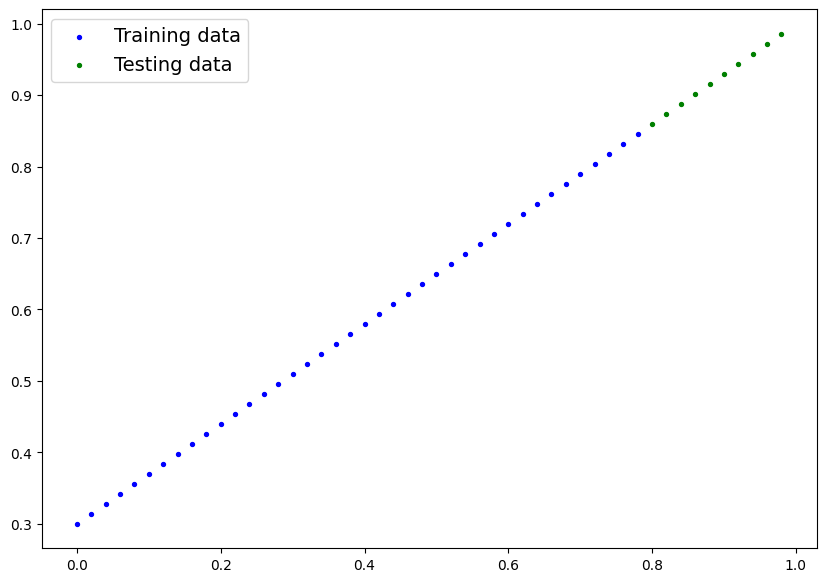

In [94]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
  plt.figure(figsize=(10, 7)) # creates a graph window with size: width = 10,height = 7


  # Plot training data in blue
  plt.scatter(train_data, train_labels, c="b", s=8, label="Training data")

  # Plot training data in green
  plt.scatter(test_data, test_labels, c="g", s=8, label="Testing data")

  if predictions is not None:
    # Plot predictions in red (predictions were made on the test data)
    plt.scatter(test_data, predictions, c="r", s=4, label="Predictions")

  plt.legend(prop={"size": 14})

plot_predictions()

In [95]:
# Subclass nn.Module to make our model
class LinearRegressionModelV2(nn.Module): # Base class for PyTorch models
  def __init__(self): #init runs when u create the model
    super().__init__() #initializes the parent nn.Module class(helps to track ur layers and parameters)

    # Use nn.Linear() for creating the model parameters
    self.linear_layer = nn.Linear(in_features=1, # (nn.Linear) automatically creates: w & b
                                  out_features=1) # Linear => y = wx+b

  #Define the forward computation (input data x flows through nn.Linear())
  def forward(self, x: torch.Tensor) -> torch.Tensor:
      return self.linear_layer(x)

#Set the manual seed when creating the model (this isnt always needed but is used for demonstrative purposes, try commenting it out and seeing what happens)
torch.manual_seed(42)
model_1 = LinearRegressionModelV2()
model_1, model_1.state_dict()

(LinearRegressionModelV2(
   (linear_layer): Linear(in_features=1, out_features=1, bias=True)
 ),
 OrderedDict([('linear_layer.weight', tensor([[0.7645]])),
              ('linear_layer.bias', tensor([0.8300]))]))

In [96]:
# Create loss function
loss_fn = nn.L1Loss() # Loss Function | MAE => Mean Absolute error

# Create optimizer: Optimizer = changes w and b to reduce that mistake
optimizer = torch.optim.SGD(params=model_1.parameters(),# optimize newly created model's parameters
                            lr=0.01) # w, b | equal; lr=learning rate


Text(0.5, 1.0, 'Prediction before training (red = random guess)')

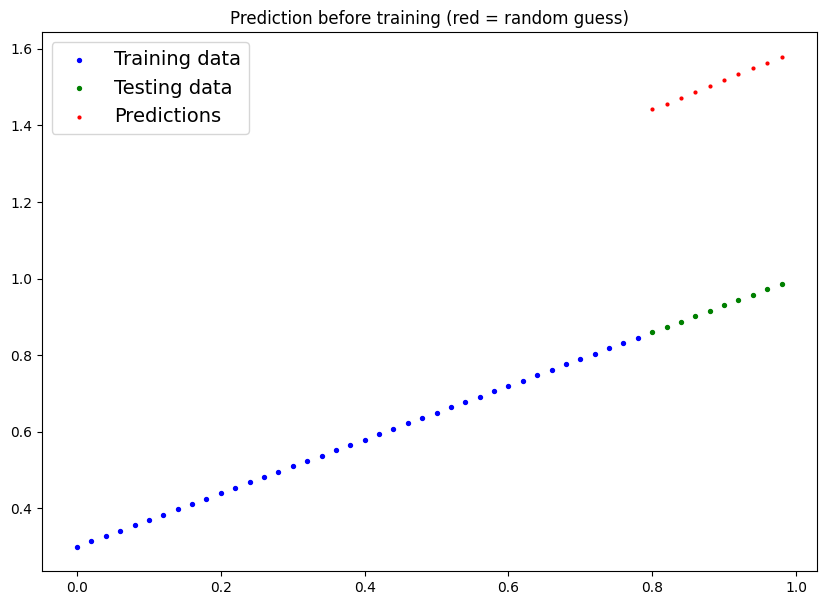

In [97]:
# See model's untrained predictions(on the test set)
model_1.eval() #

with torch.inference_mode():
  y_preds_early = model_1(X_test) #backwards

plot_predictions(predictions=y_preds_early)
plt.title("Prediction before training (red = random guess)")


In [98]:
# Set the number of epochs
epochs = 1000

#Put data on the available device
#Without this, error will happen(not all model/data on device)
X_train = X_train.to(device)
X_test = X_test.to(device)
y_train = y_train.to(device)
y_test = y_test.to(device)

for epoch in range(epochs):
  ### Training
  model_1.train() # Train mode is on by default after construction

  # 1. Forward pass
  y_pred = model_1(X_train)  #This sends your training inputs into the model

  # 2. Calculate loss
  loss = loss_fn(y_pred, y_train) #For all training values, it calculates the average error.

  # 3. Zero grad optimizer
  optimizer.zero_grad() #"Erase the previous gradient information before calculating the new one."

  # 4. Loss backward; redo again; 'backpropogation'
  loss.backward() #figures out HOW w and b should change

  # 5. Step the optimizer
  optimizer.step() #ACTUALLY changes w and b

  ### Testing
  model_1.eval() #"Stop training behavior. I want to evaluate."
  # 1. Forward pass
  with torch.inference_mode(): #"Don't track gradients because we're only checking predictions."
    test_pred = model_1(X_test)

    # 2. Calculate the loss
    test_loss = loss_fn(test_pred, y_test)

  if epochs % 100 == 0:
    print(f"Epoch: {epochs} | Loss: {loss} | Test Loss: {test_loss}")

#



Epoch: 1000 | Loss: 0.5551779866218567 | Test Loss: 0.5739762187004089
Epoch: 1000 | Loss: 0.5436569452285767 | Test Loss: 0.5605052709579468
Epoch: 1000 | Loss: 0.5321359634399414 | Test Loss: 0.5470342040061951
Epoch: 1000 | Loss: 0.5206149816513062 | Test Loss: 0.5335632562637329
Epoch: 1000 | Loss: 0.5090939998626709 | Test Loss: 0.520092248916626
Epoch: 1000 | Loss: 0.49757298827171326 | Test Loss: 0.5066213011741638
Epoch: 1000 | Loss: 0.4860519766807556 | Test Loss: 0.4931503236293793
Epoch: 1000 | Loss: 0.47453099489212036 | Test Loss: 0.47967928647994995
Epoch: 1000 | Loss: 0.4630100131034851 | Test Loss: 0.4662083089351654
Epoch: 1000 | Loss: 0.45148906111717224 | Test Loss: 0.45273739099502563
Epoch: 1000 | Loss: 0.4399680495262146 | Test Loss: 0.4392663538455963
Epoch: 1000 | Loss: 0.42844706773757935 | Test Loss: 0.42579537630081177
Epoch: 1000 | Loss: 0.41692614555358887 | Test Loss: 0.41232436895370483
Epoch: 1000 | Loss: 0.4054051339626312 | Test Loss: 0.398853361606597

In [99]:
# Turn model into evaluation mode

model_1.eval()

#Make predictions on the test data
with torch.inference_mode():
  y_preds=model_1(X_test)
y_preds

tensor([[0.8600],
        [0.8739],
        [0.8878],
        [0.9018],
        [0.9157],
        [0.9296],
        [0.9436],
        [0.9575],
        [0.9714],
        [0.9854]])

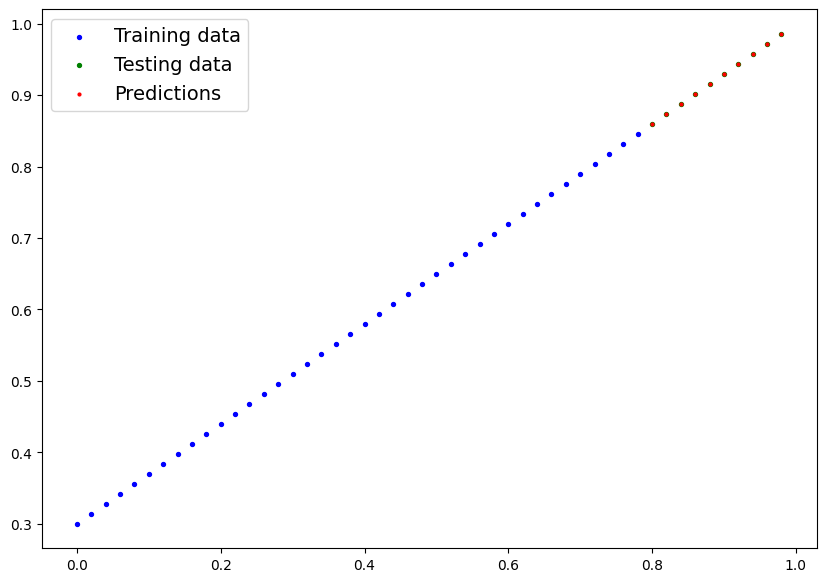

In [100]:
# Put data on the CPU and plot it
plot_predictions(predictions=y_preds)

In [101]:
torch.save(model_1.state_dict(), 'trained_model')

In [102]:
loaded_model = LinearRegressionModelV2()

loaded_model.load_state_dict(torch.load('/content/trained_model'))

loaded_model.eval()

LinearRegressionModelV2(
  (linear_layer): Linear(in_features=1, out_features=1, bias=True)
)